# TP5 · Ejercicio 2b: VAE convolucional sobre los sprites de Pokémon
**Pregunta guía.** En el ejercicio 2 el VAE generaba figuras con forma y paleta de Pokémon, pero **moteadas y borrosas**. ¿Cuánto de eso es culpa del VAE y cuánto de haber usado una MLP, que no sabe que dos píxeles vecinos están relacionados? Acá se cambia **una sola cosa**: las capas densas del codificador y del decodificador pasan a ser **convoluciones**. La pérdida, el truco de reparametrización, el optimizador, los datos y la partición son los del ejercicio 2.

**Regla del TP.** Igual que en los ejercicios 1 y 2, todo el aprendizaje está escrito a mano (`deep_conv.py`): convolución, su retropropagación y Adam. No hay diferenciación automática ni librerías de aprendizaje. Para entrenar en GPU se usa `cupy`, que ofrece la misma interfaz de arreglos que `numpy` sobre CUDA: el código es el mismo y sólo cambia dónde se hacen las sumas y los productos de matrices. En CPU el mismo archivo corre con `numpy`.

**Cómo se corrió.** `correr_ej2b.py` entrenó 13 redes en una GPU T4 x2 de Kaggle (4 h 17 min). Este notebook **carga** esos resultados de `results/`; no reentrena. El ejercicio 2 no se modifica: de él sólo se importan los datos, las métricas y la MLP ya entrenada.

| § | Contenido |
|---|---|
| 1 | Datos: los mismos sprites, a 32×32 y a 64×64 |
| 2 | De la capa densa a la convolución: cuentas y verificación del gradiente |
| 3 | Comparación con la MLP del ejercicio 2 en igualdad de condiciones |
| 4 | Curvas de entrenamiento y sobreajuste |
| 5 | Reconstrucción de Pokémon no vistos |
| 6 | Generación desde el prior y elección de una muestra nueva |
| 7 | Interpolaciones y fusiones en el espacio latente |
| 8 | Conclusiones y limitaciones |


## 1. Datos
Los mismos 809 sprites, el mismo preprocesamiento y **la misma partición** del ejercicio 2 (728 de entrenamiento, duplicados con su reflejo, y 81 Pokémon completos que el modelo nunca ve). Se usan dos resoluciones: 32×32, para comparar con la MLP sin cambiar nada más, y 64×64, para el generador final.

32x32: (1456, 3072) | 64x64: (1456, 12288) | validación: 81 | mismos Pokémon de validación: True


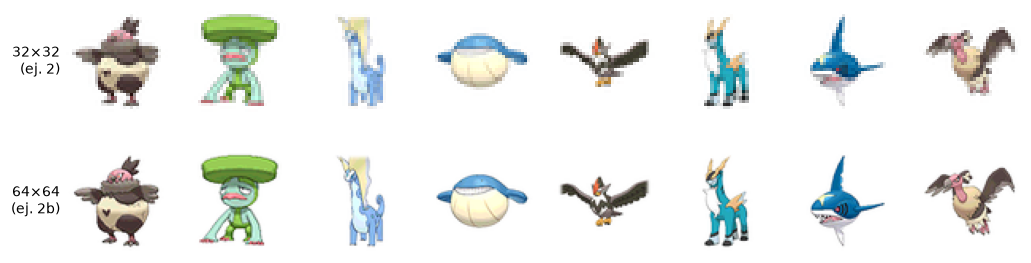

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "4")
import sys, json, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
RAIZ = Path.cwd()
EJ2 = next(p for p in (RAIZ, RAIZ.parent.parent / "Ejercicio_2" / "codigo") if (p / "experimentos.py").exists())
sys.path[:0] = [str(RAIZ), str(EJ2)]          # el código y los datos del ejercicio 2 se usan tal cual, sin modificarlos
from deep_conv import ConvVAE, cargar_conv, chequeo_gradiente, GPU
from experimentos import *
from graficos import *
cfg = cargar_config(); c = cfg["ej2_pokemon"]
RES, RES2 = RAIZ / "results", EJ2 / "results"
CONF = json.loads((RES / "config_ej2b.json").read_text())
A, B = CONF["bloque_a"], CONF["bloque_b"]

P = datos_pokemon(cfg)                                             # 32x32: la misma partición del ejercicio 2
cfg64 = copy.deepcopy(cfg); cfg64["ej2_pokemon"]["lado"] = B["lado"]
P64 = datos_pokemon(cfg64)                                         # 64x64: mismos Pokémon, misma partición
S, S64, nombres = P["shape"], P64["shape"], P["nombres"]
print("32x32:", P["Xtr"].shape, "| 64x64:", P64["Xtr"].shape, "| validación:", P["Xte"].shape[0], "| mismos Pokémon de validación:", bool((P["te"] == P64["te"]).all()))
def mosaico(filas, noms, formas, tam=1.0):
    """Como graficos.fila_comparada, pero cada fila puede tener su resolución."""
    n = len(filas[0]); fig, axs = plt.subplots(len(filas), n, figsize=(n * tam, len(filas) * tam * 1.08), squeeze=False)
    for r, (f, nom, sh) in enumerate(zip(filas, noms, formas)):
        for k in range(n):
            axs[r, k].imshow(np.clip(np.asarray(f[k]).reshape(sh), 0, 1)); axs[r, k].set_xticks([]); axs[r, k].set_yticks([])
            for s_ in axs[r, k].spines.values(): s_.set_visible(False)
        axs[r, 0].set_ylabel(nom, rotation=0, ha="right", va="center", fontsize=9)
    return fig
sel = np.random.default_rng(1).choice(len(P["X"]), 8, replace=False)
mosaico([P["X"][sel], P64["X"][sel]], ["32×32\n(ej. 2)", "64×64\n(ej. 2b)"], [S, S64], tam=1.4)
plt.show()

## 2. De la capa densa a la convolución
Una capa densa conecta cada píxel de salida con todos los de entrada: tiene que aprender desde cero que los píxeles vecinos se parecen. Una **convolución** usa el mismo núcleo chico en todas las posiciones, así que esa estructura viene dada y hay muchos menos parámetros.

**Pasada hacia adelante.** Con un núcleo $W$ de $k\times k$, la salida en la posición $(y,x)$ es $\;o_{y,x}=b+\sum_{i,j} a_{s y+i,\;s x+j}\,W_{i,j}$, donde $s$ es el paso. En `deep_conv.Conv` eso se escribe como $k^2$ productos de matrices: para cada $(i,j)$ del núcleo, la entrada desplazada se multiplica por $W_{i,j}$ y se acumula.

**Retropropagación.** Recorre las mismas $k^2$ posiciones con $\delta=\partial\mathcal{L}/\partial o$:
$$\frac{\partial\mathcal{L}}{\partial W_{i,j}}=a_{(i,j)}^{\top}\,\delta,\qquad \frac{\partial\mathcal{L}}{\partial a_{(i,j)}}\mathrel{+}=\delta\,W_{i,j}^{\top},\qquad \frac{\partial\mathcal{L}}{\partial b}=\sum\delta .$$
Para agrandar la imagen en el decodificador se repite cada píxel en un bloque de 2×2 (`Ampliar`) y después se convoluciona; el gradiente de esa repetición es la suma de cada bloque. El resto (cabezas $\mu$ y $\log\sigma^2$, reparametrización, KL cerrada, BCE desde logits) es idéntico a `deep.VAE`.

El gradiente completo se verifica con diferencias finitas, fijando el ruido $\varepsilon$:

In [2]:
print(f"cuentas en {'GPU (cupy)' if GPU else 'CPU (numpy)'} | error relativo máximo del gradiente del VAE convolucional: {chequeo_gradiente():.2e}")
m = ConvVAE(B["lado"], B["canales"], B["latente"]); n64 = sum(p.size for p in m.params)
m = ConvVAE(A["lado"], A["canales"], A["latente"]); n32 = sum(p.size for p in m.params)
n_mlp = sum(p.size for p in VAE(3072, c["hidden"], 32, c["activacion"]).params)
print(f"parámetros: MLP del ej. 2 (32x32) {n_mlp:,} | convolucional 32x32 {n32:,} | convolucional 64x64 {n64:,}".replace(",", "."))

cuentas en CPU (numpy) | error relativo máximo del gradiente del VAE convolucional: 1.38e-08


parámetros: MLP del ej. 2 (32x32) 3.437.120 | convolucional 32x32 466.691 | convolucional 64x64 5.925.123


### 2.1 Arquitectura y entrenamiento
| | Conv 32×32 (bloque A) | Conv 64×64 (bloque B) |
|---|---|---|
| Codificador | 3 convoluciones 4×4 de paso 2 (32, 64, 128 canales) + ReLU | 4 convoluciones (64, 128, 256, 512 canales) |
| Latente | $d=32$ (igual que el ej. 2) | $d=64$ |
| Decodificador | densa, y por nivel: ampliar ×2, convolución 3×3, ReLU | ídem, un nivel más |
| Entrenamiento | Adam, lr $10^{-3}$, lotes de 64, 600 épocas | Adam, lr $5\cdot10^{-4}$, 3000 épocas |
| Corridas | $\beta\in\{0;1\}$ × aumento sí/no × 3 semillas = 12 redes | $\beta=1$, 1 red |

- **La red convolucional de 32×32 tiene 7 veces menos parámetros que la MLP** (0,47 contra 3,44 millones).
- **Calentamiento de $\beta$:** sube linealmente de 0 a su valor en las primeras épocas, para que el decodificador aprenda a usar el código antes de que el KL lo apriete.
- **Aumento de datos:** en cada lote los sprites se corren al azar hasta ±2 píxeles (±4 a 64×64), rellenando con blanco.
- **Dos puntos de control por red:** la época con mejor $-$ELBO de validación (`mejor_val`) y la última (`final`).

## 3. Comparación con la MLP en igualdad de condiciones (32×32)
Mismas columnas y mismas funciones de medición que el ejercicio 2 (`experimentos.calidad_pokemon`): BCE de reconstrucción en Pokémon no vistos, KL, distancia de Fréchet de las muestras del prior al conjunto (con su piso: Pokémon reales no vistos) y fracción de casi copias. Medias de 3 semillas.

In [3]:
db = pd.DataFrame(json.loads((RES / "ej2b_barrido.json").read_text()))
mlp = pd.DataFrame(json.loads((RES2 / "ej2p_barrido.json").read_text())); mlp = mlp[mlp.latent == 32]
cols = ["rec_val", "kl", "std_mu", "fd", "frac_copia", "mae_val"]
a = db[db.bloque == "bloque_a"]
tabla = pd.concat([mlp[mlp.beta.isin(A["betas"])].assign(modelo="MLP (ej. 2)", desplazar=0, punto="final", epoca=c["epocas"]),
                   a.assign(modelo="Conv (ej. 2b)")])
res = tabla.groupby(["beta", "modelo", "desplazar", "punto"])[cols + ["epoca"]].mean().round(2)
fd_ref = float(a.fd_ref.mean()); print(f"Piso de la distancia de Fréchet (Pokémon reales no vistos): {fd_ref:.1f}"); res

Piso de la distancia de Fréchet (Pokémon reales no vistos): 4.1


rec_val      kl  std_mu     fd  \
beta modelo        desplazar punto                                       
0.0  Conv (ej. 2b) 0         final       847.50  269.42    2.41  20.45   
                             mejor_val   754.44  187.02    1.09  24.77   
                   2         final       734.77  231.60    1.86  23.00   
                             mejor_val   728.55  214.84    1.56  25.36   
     MLP (ej. 2)   0         final       801.59  298.69    2.64  19.13   
1.0  Conv (ej. 2b) 0         final       797.73   47.18    0.97   5.18   
                             mejor_val   754.32   43.16    0.95   8.44   
                   2         final       736.41   42.13    0.93   5.91   
                             mejor_val   732.58   40.64    0.92   6.51   
     MLP (ej. 2)   0         final       815.41   37.09    0.98   6.77   

                                        frac_copia  mae_val   epoca  
beta modelo        desplazar punto                                   
0.0  Conv (ej. 2b) 0         final            0.00     0.08  600.00  
                             mejor_val        0.00     0.07   50.00  
                   2         final            0.00     0.06  600.00  
                             mejor_val        0.00     0.06  250.00  
     MLP (ej. 2)   0         final            0.00     0.07  300.00  
1.0  Conv (ej. 2b) 0         final            0.01     0.07  600.00  
                             mejor_val        0.01     0.07   83.33  
                   2         final            0.02     0.06  600.00  
                             mejor_val        0.01     0.06  300.00  
     MLP (ej. 2)   0         final            0.01     0.08  300.00

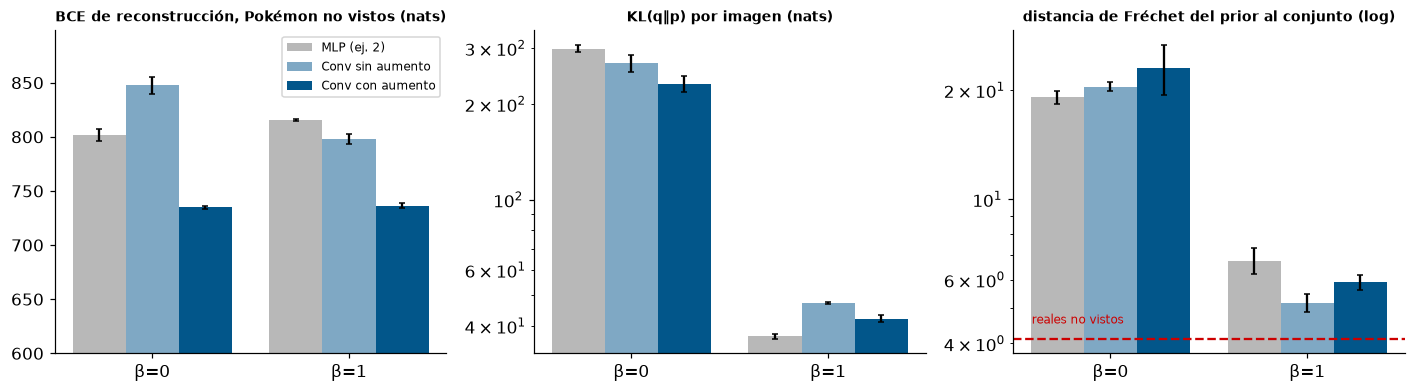

In [4]:
PUNTO, AUM = "final", 0        # punto de control y aumento que se usan de acá en adelante (ver la lectura)
def fila(modelo, beta, desp=0, punto="final"):
    g = tabla[(tabla.modelo == modelo) & (tabla.beta == beta) & (tabla.desplazar == desp) & (tabla.punto == punto)]
    return g[cols].mean(), g[cols].std().fillna(0)
series = [("MLP (ej. 2)", GRIS, ("MLP (ej. 2)", 0, "final")), ("Conv sin aumento", "#7FA8C4", ("Conv (ej. 2b)", 0, PUNTO)),
          ("Conv con aumento", AZUL, ("Conv (ej. 2b)", A["desplazar"][-1], PUNTO))]
fig, axs = plt.subplots(1, 3, figsize=(13, 3.7))
for ax, (cc, tit, log) in zip(axs, [("rec_val", "BCE de reconstrucción, Pokémon no vistos (nats)", False),
                                    ("kl", "KL(q‖p) por imagen (nats)", True), ("fd", "distancia de Fréchet del prior al conjunto (log)", True)]):
    for k, (lab, col, (mod, desp, punto)) in enumerate(series):
        ms = [fila(mod, b, desp, punto) for b in A["betas"]]
        ax.bar(np.arange(len(A["betas"])) + (k - 1) * .27, [m[cc] for m, _ in ms], .27, yerr=[s[cc] for _, s in ms], color=col, capsize=2, label=lab)
    ax.set_xticks(range(len(A["betas"]))); ax.set_xticklabels([f"β={b:g}" for b in A["betas"]]); ax.set_title(tit, fontsize=9)
    if log: ax.set_yscale("log")
axs[2].axhline(fd_ref, color=ROJO, ls="--"); axs[2].text(-.4, fd_ref * 1.1, "reales no vistos", color=ROJO, fontsize=8)
axs[0].set_ylim(600, None); axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Lectura** (medias de 3 semillas, $\beta=1$, $d=32$).
1. **La convolución mejora las dos cosas a la vez.** Frente a la MLP, la BCE en Pokémon no vistos baja de 815 a 798 nats y la distancia de Fréchet de las muestras baja de **6,8 a 5,2**, con un piso de 4,1. Con 7 veces menos parámetros, la red convolucional recorre más de la mitad de lo que le faltaba a la MLP para llegar al piso.
2. **El aumento de datos mejora la reconstrucción y no las muestras.** Con corrimientos la BCE baja a 736, pero el Fréchet sube a 5,9: el modelo aprende a dibujar sprites corridos, que el conjunto de referencia (centrado) no tiene.
3. **El punto de mejor validación no es el mejor generador.** Cortar en la época de mejor $-$ELBO (≈ 83) da mejor reconstrucción de Pokémon no vistos (754 contra 798) pero peores muestras (Fréchet 8,4 contra 5,2). Entrenar más allá sobreajusta la reconstrucción y, a la vez, afila el decodificador. Las casi copias siguen en 1 %, así que no es memorización lisa y llana. De acá en adelante se usa el punto `final` sin aumento para 32×32.
4. **$\beta=0$ sigue sin poder generar** (Fréchet ≈ 20, igual que la MLP con $\beta=0$): la conclusión del ejercicio 2 no depende de la arquitectura.

## 4. Curvas de entrenamiento

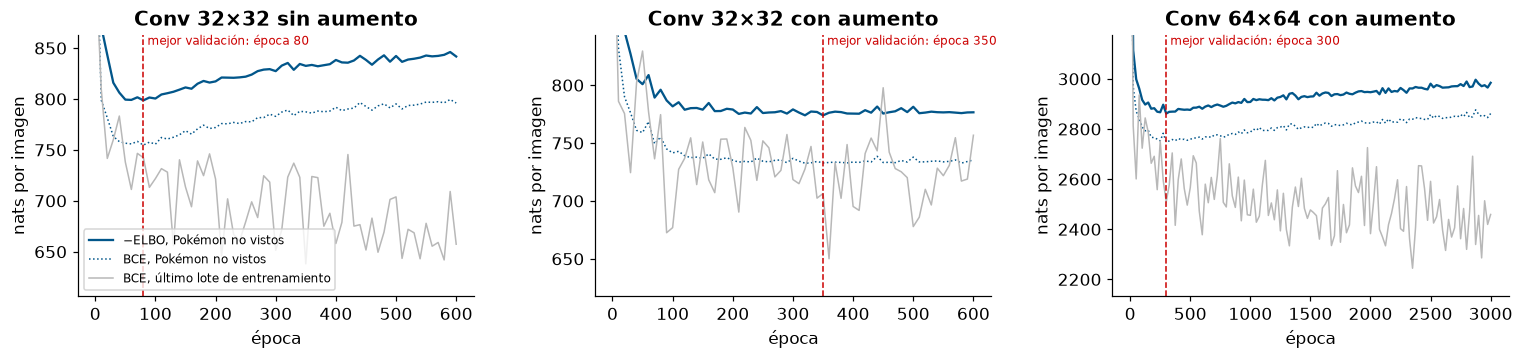

In [5]:
def cargar(lado, beta, desp, punto=None, s=0):
    return cargar_conv(RES / f"ej2b_L{lado}_b{beta:g}_a{desp}_s{s}_{punto or PUNTO}.npz")
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, (lado, desp, tit) in zip(axs, [(32, 0, "Conv 32×32 sin aumento"), (32, A["desplazar"][-1], "Conv 32×32 con aumento"), (B["lado"], B["desplazar"][0], f"Conv {B['lado']}×{B['lado']} con aumento")]):
    h = pd.DataFrame(cargar(lado, 1.0, desp, "final")[1]); mejor = h.loc[h.val_elbo.idxmin()]
    ax.plot(h.epoch, h.val_elbo, color=AZUL, label="−ELBO, Pokémon no vistos"); ax.plot(h.epoch, h.rec_val, color=AZUL, ls=":", lw=1, label="BCE, Pokémon no vistos")
    ax.plot(h.epoch, h.rec, color=GRIS, lw=1, label="BCE, último lote de entrenamiento")
    ax.set_title(tit); ax.set_xlabel("época"); ax.set_ylabel("nats por imagen"); ax.set_ylim(h.rec.min() * .95, h.val_elbo[h.epoch > 20].max() * 1.02)
    ax.axvline(mejor.epoch, color=ROJO, ls="--", lw=1); ax.text(mejor.epoch, ax.get_ylim()[1], f" mejor validación: época {mejor.epoch:.0f}", color=ROJO, fontsize=8, va="top")
axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()

La línea roja marca la época de mejor validación. **Sin aumento, la red sobreajusta desde la época ≈ 80:** la BCE de entrenamiento sigue bajando y la de validación sube. **Con aumento la validación queda plana** hasta el final, que es el efecto buscado. A 64×64 el mínimo de validación está en la época 300 y después empeora despacio durante las 2700 épocas restantes: entrenar más tiempo no hace que el modelo generalice mejor, sólo que recuerde mejor los 728 sprites que vio.

## 5. Reconstrucción de Pokémon que el modelo nunca vio

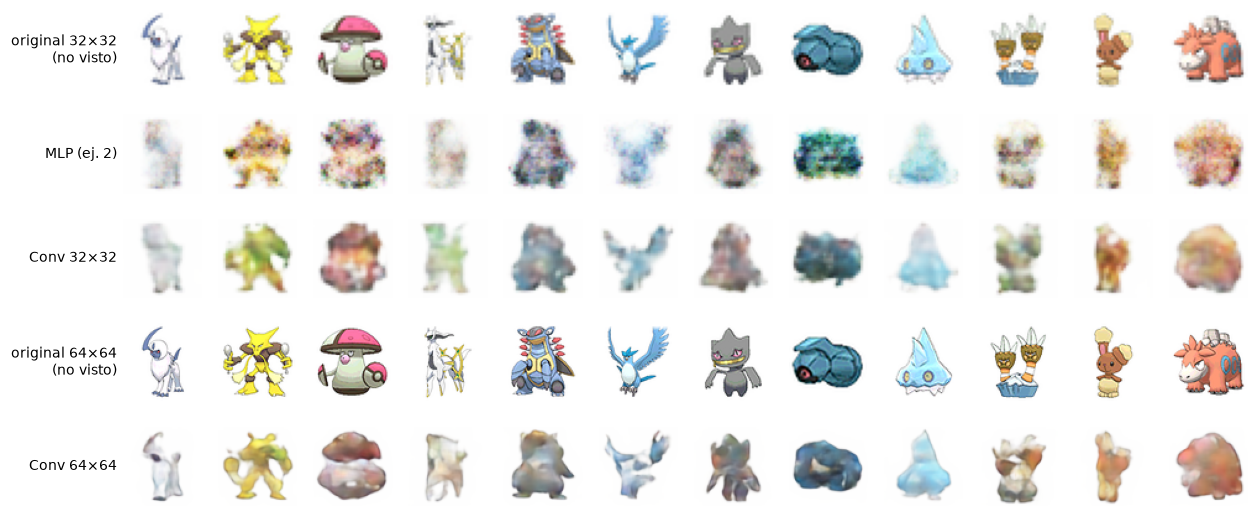

['absol', 'alakazam', 'amoonguss', 'arceus', 'armaldo', 'articuno', 'banette', 'beldum', 'bergmite', 'binacle', 'buneary', 'camerupt']


In [6]:
vM, _ = vae_pokemon(P, cfg, 1.0, 32, RES2)                          # MLP del ejercicio 2 (se carga, no se reentrena)
vC, _ = cargar(32, 1.0, AUM); aC, _ = cargar(32, 0.0, AUM)          # convolucional 32x32: VAE y autoencoder (β=0)
vG, hG = cargar(B["lado"], 1.0, B["desplazar"][0])                  # convolucional 64x64: el generador final
k = np.arange(12)
mosaico([P["Xte"][k], vM.reconstruct(P["Xte"][k]), vC.reconstruct(P["Xte"][k]), P64["Xte"][k], vG.reconstruct(P64["Xte"][k])],
        ["original 32×32\n(no visto)", "MLP (ej. 2)", "Conv 32×32", "original 64×64\n(no visto)", f"Conv {B['lado']}×{B['lado']}"], [S, S, S, S64, S64], tam=1.1)
plt.show(); print([nombres[i] for i in P["te"][k]])

La MLP devuelve la silueta cubierta de **ruido de colores**. La red convolucional devuelve **manchas de color lisas y coherentes**: el amarillo de Alakazam, el sombrero rojo de Amoonguss, las alas de Articuno. A 64×64 las formas son más definidas. En ningún caso aparecen ojos ni contornos: de un Pokémon que nunca vio, el modelo recupera forma y paleta, no detalle.

## 6. Generación de Pokémon nuevos (consigna 2c)
Muestras $z\sim\mathcal{N}(0,I)$ decodificadas por cada modelo.

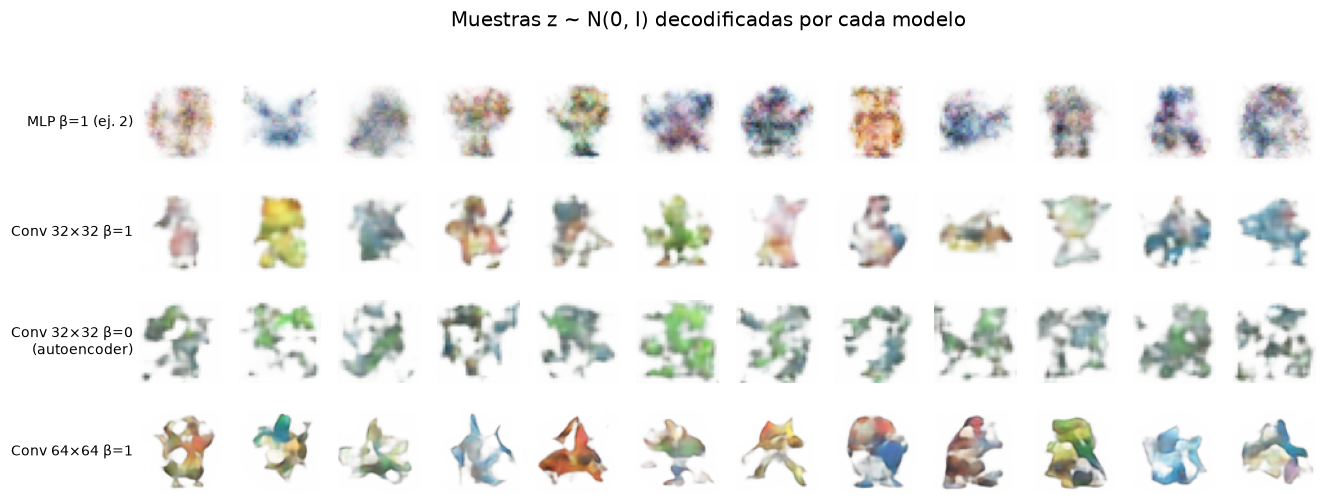

32×32, mismas métricas del ejercicio 2:


  MLP  β=1: Fréchet    7.4 (piso 4.1) | distancia mediana al vecino 8.2 (real no visto 9.7) | copias 0.008


  Conv β=1: Fréchet    5.1 (piso 4.1) | distancia mediana al vecino 8.1 (real no visto 9.7) | copias 0.011


  Conv β=0: Fréchet   20.1 (piso 4.1) | distancia mediana al vecino 10.2 (real no visto 9.7) | copias 0.000


64×64: Conv β=1: Fréchet 29.3 (piso 16.6) | distancia mediana al vecino 18.4 (real no visto 22.1) | copias 0.007
rugosidad (diferencia media entre píxeles vecinos) y área de la figura:


  MLP 32   rugosidad 0.0451 (reales 0.0585) | área 0.46 (reales 0.34)


  Conv 32  rugosidad 0.0362 (reales 0.0585) | área 0.37 (reales 0.34)


  Conv 64  rugosidad 0.0229 (reales 0.0457) | área 0.33 (reales 0.31)


In [7]:
rng = np.random.default_rng(7)
Z, ZG = rng.standard_normal((12, 32)), rng.standard_normal((12, B["latente"]))
mosaico([vM.decode(Z), vC.decode(Z), aC.decode(Z), vG.decode(ZG)],
        ["MLP β=1 (ej. 2)", "Conv 32×32 β=1", "Conv 32×32 β=0\n(autoencoder)", f"Conv {B['lado']}×{B['lado']} β=1"], [S, S, S, S64], tam=1.15)
plt.suptitle("Muestras z ~ N(0, I) decodificadas por cada modelo", y=1.0); plt.show()
def rugosidad(X, sh): return float(np.abs(np.diff(X.reshape(-1, *sh), axis=2)).mean())
def area(X): return ((X.reshape(len(X), -1, 3)).min(2) < 0.9).mean(1)
Zm = np.random.default_rng(3).standard_normal((2000, 32)); ZmG = np.random.default_rng(3).standard_normal((2000, B["latente"]))
GM, GC, GV = vM.decode(Zm), vC.decode(Zm), vG.decode(ZmG)
rasgos = base_pca(P["Xtr"], c["componentes_pca"])
print("32×32, mismas métricas del ejercicio 2:")
for nom, m_ in [("MLP  β=1", vM), ("Conv β=1", vC), ("Conv β=0", aC)]:
    q = calidad_pokemon(m_, P, cfg, rasgos=rasgos)
    print(f"  {nom}: Fréchet {q['fd']:6.1f} (piso {q['fd_ref']:.1f}) | distancia mediana al vecino {q['d_gen_med']:.1f} (real no visto {q['d_real_med']:.1f}) | copias {q['frac_copia']:.3f}")
q = calidad_pokemon(vG, P64, cfg64)
print(f"{B['lado']}×{B['lado']}: Conv β=1: Fréchet {q['fd']:.1f} (piso {q['fd_ref']:.1f}) | distancia mediana al vecino {q['d_gen_med']:.1f} (real no visto {q['d_real_med']:.1f}) | copias {q['frac_copia']:.3f}")
print("rugosidad (diferencia media entre píxeles vecinos) y área de la figura:")
for nom, G_, X_, sh in [("MLP 32", GM, P["X"], S), ("Conv 32", GC, P["X"], S), (f"Conv {B['lado']}", GV, P64["X"], S64)]:
    print(f"  {nom:8s} rugosidad {rugosidad(G_, sh):.4f} (reales {rugosidad(X_, sh):.4f}) | área {area(G_).mean():.2f} (reales {area(X_).mean():.2f})")

**Lectura.**
- **El moteado desaparece.** Las muestras convolucionales son figuras de colores lisos sobre fondo blanco; las de la MLP están cubiertas de puntos. En números, a 32×32 el Fréchet baja de 7,4 a 5,1 (piso 4,1) para la semilla 0.
- **El área de la figura ahora coincide con la de los sprites reales:** 0,37 (conv 32) y 0,33 (conv 64) contra 0,34 y 0,31 de los reales; la MLP daba 0,46 porque su borde borroso contaba como figura.
- **Siguen siendo más lisas que un sprite real** (rugosidad 0,023 contra 0,046 a 64×64): no tienen contornos negros ni detalles finos.
- **Siendo honestos: no se reconocen como Pokémon concretos.** Son criaturas abstractas con la forma general, el tamaño y la paleta del conjunto. A 64×64 el Fréchet (29,3) queda más lejos de su piso (16,6) que a 32×32: a más resolución hay más detalle que el modelo no puede inventar con 728 ejemplos.

### 6.1 Elegir una muestra nueva
Mismo procedimiento que el ejercicio 2 (§5.2), ahora con el modelo de 64×64: de 2000 muestras del prior se retienen las que no son copias y tienen área y contraste de sprite real, y se ordenan por cercanía al conjunto en el espacio PCA.

860 de 2000 muestras no son copias y tienen área y contraste de sprite real
distancia mediana al vecino de entrenamiento en el espacio PCA: muestras filtradas 9.57 | Pokémon reales no vistos 9.08


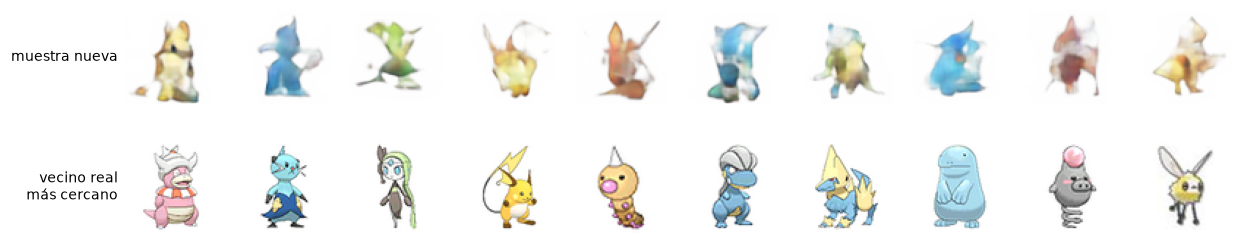

vecinos: ['slowking (esp.)', 'dewott (esp.)', 'meloetta-aria', 'raichu (esp.)', 'weedle', 'bagon (esp.)', 'manectric', 'quagsire', 'spoink (esp.)', 'cutiefly (esp.)']


In [8]:
def contraste(X):
    R = X.reshape(len(X), -1, 3); m_ = R.min(2) < 0.9
    return np.array([R[i][m_[i]].std() if m_[i].sum() > 5 else 0.0 for i in range(len(X))])
en_rango = lambda v, ref: (v >= np.percentile(ref, 10)) & (v <= np.percentile(ref, 90))
Q, Gc = P64, GV; n_orig = len(Q["tr"])
dn = dist_vecino(Gc, Q["Xtr"]); med = np.median(dist_vecino(Q["Xte"], Q["Xtr"]))
ok = np.where((dn > 0.5 * med) & en_rango(area(Gc), area(Q["X"])) & en_rango(contraste(Gc), contraste(Q["X"])))[0]
rasgos64 = base_pca(Q["Xtr"], c["componentes_pca"]); Ftr, Fg = rasgos64(Q["Xtr"]), rasgos64(Gc)
dpca, dpca_real = dist_vecino(Fg, Ftr), np.median(dist_vecino(rasgos64(Q["Xte"]), Ftr))
print(f"{len(ok)} de {len(Gc)} muestras no son copias y tienen área y contraste de sprite real")
print(f"distancia mediana al vecino de entrenamiento en el espacio PCA: muestras filtradas {np.median(dpca[ok]):.2f} | Pokémon reales no vistos {dpca_real:.2f}")
nombre_tr = lambda j: nombres[Q["tr"][j % n_orig]] + (" (esp.)" if j >= n_orig else "")
vec = lambda i: int(np.argmin(((Ftr - Fg[i]) ** 2).sum(1)))
elegidos, usados = [], set()
for i in ok[np.argsort(dpca[ok])]:
    n_ = nombres[Q["tr"][vec(i) % n_orig]]
    if n_ not in usados: elegidos.append(i); usados.add(n_)
    if len(elegidos) == 10: break
vecinos = [vec(i) for i in elegidos]
mosaico([Gc[elegidos], Q["Xtr"][vecinos]], ["muestra nueva", "vecino real\nmás cercano"], [S64, S64], tam=1.3); plt.show()
print("vecinos:", [nombre_tr(j) for j in vecinos])

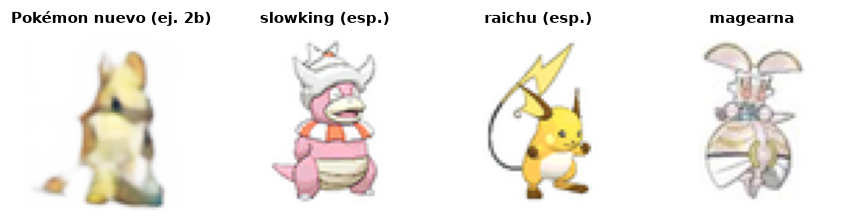

en píxeles: vecino más cercano a 18.0 (umbral de copia 11.1; un Pokémon real no visto, mediana 22.1)
en el espacio PCA: vecino más cercano a 4.89 (un Pokémon real no visto, mediana 9.08)


área de la figura 0.31 y contraste 0.181 (reales: mediana 0.31 y 0.217)


In [9]:
ELEGIDA = 0                    # elegida a ojo entre las 10 de arriba
i = elegidos[ELEGIDA]; g = Gc[i]
d_f = np.sqrt(((Ftr - Fg[i]) ** 2).sum(1)); cerca = []
for j in np.argsort(d_f):
    if nombres[Q["tr"][j % n_orig]] not in [nombres[Q["tr"][k_ % n_orig]] for k_ in cerca]: cerca.append(j)
    if len(cerca) == 3: break
fig = mostrar_imagenes(np.array([g] + [Q["Xtr"][j] for j in cerca]), S64, ["Pokémon nuevo (ej. 2b)"] + [nombre_tr(j) for j in cerca], ncols=4, tam=2.4, ax_title_size=10)
plt.show()
print(f"en píxeles: vecino más cercano a {dn[i]:.1f} (umbral de copia {0.5 * med:.1f}; un Pokémon real no visto, mediana {med:.1f})")
print(f"en el espacio PCA: vecino más cercano a {dpca[i]:.2f} (un Pokémon real no visto, mediana {dpca_real:.2f})")
print(f"área de la figura {area(g[None])[0]:.2f} y contraste {contraste(g[None])[0]:.3f} (reales: mediana {np.median(area(Q['X'])):.2f} y {np.median(contraste(Q['X'])):.3f})")

**¿Pertenece al conjunto?** La elegida es una **criatura amarilla y crema, erguida, con orejas en punta**; sus vecinos son Slowking, Raichu y Magearna, y no es ninguno.
- **No es una copia:** en píxeles está a 18,0 de su vecino más cercano (umbral 11,1).
- **Está más cerca del conjunto que un Pokémon real no visto típico:** 4,89 en el espacio PCA contra una mediana de 9,08.
- **Tiene área y contraste de sprite** (0,31 y 0,181 contra medianas de 0,31 y 0,217).
- **860 de 2000 muestras pasan el filtro** (629 con la MLP del ejercicio 2) y, como grupo, quedan a 9,57 del conjunto contra 9,08 de los Pokémon reales nuevos.

Frente a la muestra elegida en el ejercicio 2, la figura es más limpia y definida. Sigue sin tener ojos ni contorno.

## 7. Interpolaciones y fusiones
### 7.1 Interpolación entre dos Pokémon de entrenamiento

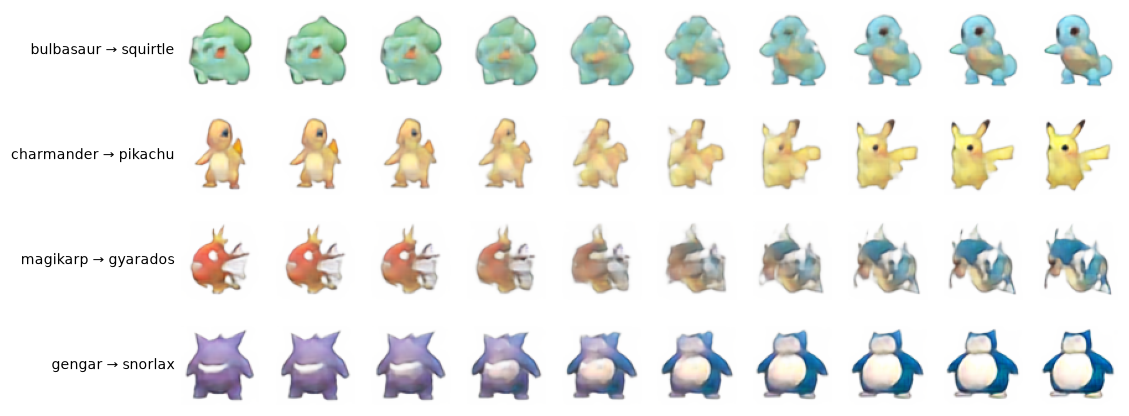

In [10]:
pares = [("bulbasaur", "squirtle"), ("charmander", "pikachu"), ("magikarp", "gyarados"), ("gengar", "snorlax")]
X_por_nombre = {n_: Q["X"][k_] for k_, n_ in enumerate(nombres)}; ts = np.linspace(0, 1, 10)
filas, nom = [], []
for a_, b_ in pares:
    za, zb = vG.encode(np.array([X_por_nombre[a_], X_por_nombre[b_]]))[0]
    filas.append(vG.decode(np.array([(1 - t) * za + t * zb for t in ts]))); nom.append(f"{a_} → {b_}")
mosaico(filas, nom, [S64] * len(filas), tam=1.1); plt.show()

En los extremos de cada fila el modelo **reconstruye casi perfecto** a Bulbasaur, Charmander, Pikachu o Snorlax, con ojos incluidos. Son Pokémon de entrenamiento: el decodificador de 64×64 los recuerda. Lo interesante está en el medio.

### 7.2 Otra forma de generar: el punto medio entre dos Pokémon
Muestrear $z\sim\mathcal{N}(0,I)$ cae casi siempre lejos de cualquier dato, donde el decodificador sólo puede dar formas genéricas. Otra muestra legítima del modelo generativo es decodificar **un código que no es el de ningún dato pero está entre dos**: $z=\tfrac12(\mu_A+\mu_B)$. Se prueba con $B$ igual al vecino más cercano de $A$ en el espacio latente y con $B$ al azar; como control se muestra $A$ más el ruido de su propio posterior.

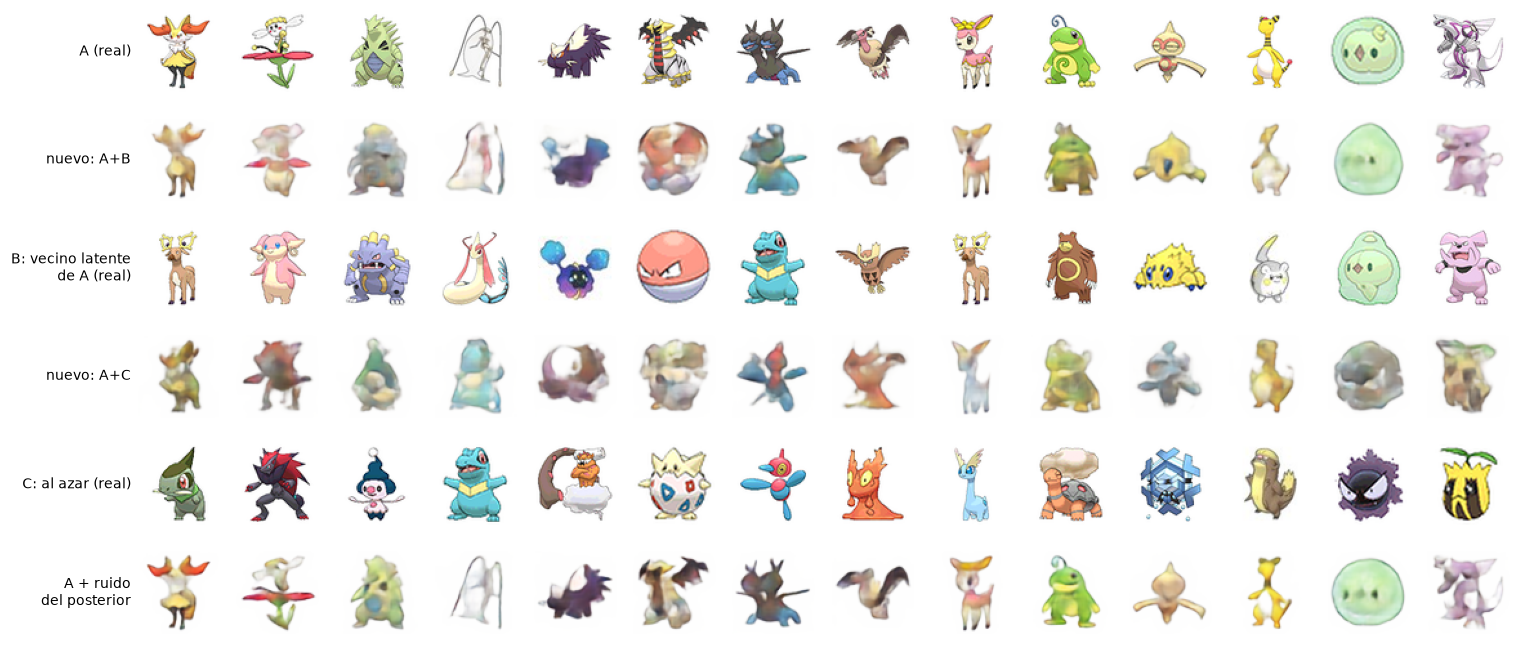

umbral de copia en píxeles: 11.1 (un Pokémon real no visto, mediana 22.1)
A+B (vecinos): distancia mediana al dato más cercano 13.7 | por encima del umbral 13 de 14
A+C (al azar): distancia mediana 19.0 | por encima del umbral 13 de 14
A + ruido:     distancia mediana 9.3 | por encima del umbral 1 de 14
pares A+B: ['braixen+stantler', 'flabebe+audino', 'tyranitar+exploud', 'pheromosa+milotic', 'stunky+cosmog', 'giratina-altered+voltorb', 'zweilous+totodile', 'mandibuzz+noctowl', 'deerling+stantler', 'politoed+ursaring', 'baltoy+joltik', 'ampharos+togedemaru', 'solosis+duosion', 'palkia+granbull']


In [11]:
Xo = Q["Xtr"][:n_orig]; mu, lv = vG.encode(Xo)                      # códigos de los Pokémon de entrenamiento (sin espejar)
d2 = ((mu[:, None] - mu[None]) ** 2).sum(2); np.fill_diagonal(d2, np.inf)
rng = np.random.default_rng(0); ia = rng.choice(n_orig, 14, replace=False); ib = d2[ia].argmin(1)   # B = vecino más cercano de A en el espacio latente
F = vG.decode(0.5 * (mu[ia] + mu[ib]))                               # punto medio entre los dos códigos
V = vG.decode(mu[ia] + np.exp(.5 * lv[ia]) * rng.standard_normal(mu[ia].shape))   # A más el ruido de su propio posterior
ic = rng.choice(n_orig, 14); F2 = vG.decode(0.5 * (mu[ia] + mu[ic]))  # punto medio con un Pokémon cualquiera
mosaico([Xo[ia], F, Xo[ib], F2, Xo[ic], V], ["A (real)", "nuevo: A+B", "B: vecino latente\nde A (real)", "nuevo: A+C", "C: al azar (real)", "A + ruido\ndel posterior"], [S64] * 6, tam=1.15); plt.show()
dF, dF2, dV = dist_vecino(F, Q["Xtr"]), dist_vecino(F2, Q["Xtr"]), dist_vecino(V, Q["Xtr"])
print(f"umbral de copia en píxeles: {0.5 * med:.1f} (un Pokémon real no visto, mediana {med:.1f})")
print(f"A+B (vecinos): distancia mediana al dato más cercano {np.median(dF):.1f} | por encima del umbral {int((dF > 0.5 * med).sum())} de {len(dF)}")
print(f"A+C (al azar): distancia mediana {np.median(dF2):.1f} | por encima del umbral {int((dF2 > 0.5 * med).sum())} de {len(dF2)}")
print(f"A + ruido:     distancia mediana {np.median(dV):.1f} | por encima del umbral {int((dV > 0.5 * med).sum())} de {len(dV)}")
print("pares A+B:", [f"{nombres[Q['tr'][i]]}+{nombres[Q['tr'][j]]}" for i, j in zip(ia, ib)])

**Lectura.**
- **Las fusiones entre vecinos latentes son las muestras más parecidas a un Pokémon de todo el trabajo:** conservan cuerpo, patas y una paleta coherente, porque los dos padres ya se parecían. Casi todas quedan por encima del umbral de copia (ver la salida de arriba), así que son figuras nuevas y no un padre retocado.
- **Las fusiones con un Pokémon al azar** vuelven a ser manchas: el punto medio entre dos códigos lejanos cae en una zona que el decodificador conoce tan poco como una muestra del prior.
- **$A$ más el ruido de su posterior es casi $A$** y en general queda por debajo del umbral: es una copia con variaciones, no una muestra nueva. Sirve para ver que el posterior de cada dato es angosto ($\sigma\approx0{,}15$).

Es la misma lección del ejercicio 1, ahora medida: el decodificador dibuja bien **cerca de los códigos que vio**, y el VAE consigue que esos códigos estén lo bastante juntos como para que el punto medio entre dos vecinos también sirva.

### 7.3 Continuación
La idea de generar **cerca de los datos** en lugar de muestrear del prior se desarrolla en el ejercicio 2c (`ejercicio2c_pokemon_cerca_de_datos.ipynb`), que usa este mismo modelo de 64×64 sin reentrenarlo.

## 8. Conclusiones y limitaciones
1. **Parte del problema del ejercicio 2 era la MLP.** Cambiando sólo las capas densas por convoluciones (misma pérdida, datos, latente y métricas), la distancia de Fréchet de las muestras baja de 6,8 a 5,2 (piso 4,1), la BCE en Pokémon no vistos baja de 815 a 798 nats y el ruido de colores desaparece, con 7 veces menos parámetros.
2. **La otra parte es del VAE y de los datos, y no se arregla con más cómputo.** Cuatro horas de GPU y una red de 5,9 millones de parámetros a 64×64 dan figuras más limpias y definidas, pero no ojos ni contornos: con 728 Pokémon distintos, uno de cada uno, y una verosimilitud que promedia píxel a píxel, el modelo aprende forma y paleta, no detalle. La validación deja de mejorar en la época 300 de 3000.
3. **Mejor validación no es mejor generador:** cortar en el mínimo del $-$ELBO de validación da peores muestras que seguir entrenando.
4. **El aumento con corrimientos** elimina el sobreajuste de la reconstrucción (798 → 736 nats) pero no mejora las muestras.
5. **Generación (2c):** la muestra elegida del prior no es copia, tiene área y contraste de sprite y está más cerca del conjunto que un Pokémon real no visto típico. Las figuras más convincentes no salen del prior sino de **mezclar un Pokémon con sus vecinos latentes** (§7.2 y ejercicio 2c): eligiendo las más nítidas que no son copia se obtienen criaturas con contorno y ojos, a costa de parecerse a su base.
6. **Limitaciones.** Una sola semilla para el modelo de 64×64. El Fréchet sobre 20 componentes principales no ve detalle fino, así que premia formas y colores correctos aunque falten los ojos. La elección de la muestra y de las fusiones tiene una parte hecha a ojo. Las métricas de 64×64 no son comparables con las de 32×32.

**Qué haría falta para ir más lejos:** más ejemplos por especie (sprites de otras generaciones y ángulos), o un modelo que no promedie píxeles (pérdida adversaria o difusión), que ya queda fuera de la consigna.